# Convergencia: el plan ganador contra un plan aleatorio y el greedy, dia a dia

**Pregunta.** Partiendo del deposito tal como esta, cuanto menos camina un picker con el plan ganador
que con un plan aleatorio y que con el greedy (lo mas pedido, lo mas cerca del dock), los tres entrando al
deposito de la misma manera; como cambian esas diferencias a lo largo de los 72 dias de test; y si llegan
a estabilizarse.

**Por que estos dos planes.** El aleatorio es el plan que no usa ningun dato: cada SKU va a una ubicacion
sorteada. El greedy es el plan clasico: usa la demanda de cada SKU, pero no que SKUs se piden juntos. Si
los tres se simulan exactamente igual, la diferencia con el aleatorio es lo que gana el ganador por usar
los datos, y la diferencia con el greedy, lo que gana por usar que SKUs se piden juntos (el merchant).

**Contenido.**
0. Las corridas.
1. Como se simula y que se mide.
2. Las simulaciones.
3. El test completo.
4. Dia a dia.
5. Se estabilizo?
6. Cuanto falta para el techo.
7. Lectura.

## 0. Las corridas

Todas las corridas usan los mismos datos y el mismo simulador, y todas menos el techo parten del deposito
real, tal como esta al empezar el test. Difieren en tres decisiones: que plan se quiere alcanzar, como
entra ese plan al deposito y como se arman los batches. Cada una cambia una sola cosa respecto de la
anterior; aleatorio, greedy y ganador solo difieren en el plan.

| corrida | plan | como entra el plan | batches |
|---|---|---|---|
| hoy | ninguno: el deposito sigue como esta | no entra: un SKU agotado se muda, con probabilidad 0,9, a un hueco libre al azar, como en los datos (reposicion `random`) | FIFO |
| hoy con re-batching | ninguno | no entra (reposicion `random`) | re-batching, $W = 4$ |
| aleatorio | metodo `random`: cada SKU en una ubicacion sorteada; tres sorteos | regla `plan_aisle` | re-batching, $W = 4$ |
| greedy | `demand_greedy`: los SKUs mas pedidos en las ubicaciones mas cercanas al dock | regla `plan_aisle` | re-batching, $W = 4$ |
| **ganador** | `merchant_aisle_fill`: los SKUs de cada merchant juntos, en un pasillo o dos contiguos | regla `plan_aisle` | re-batching, $W = 4$ |
| techo | `merchant_aisle_fill` | aplicado entero antes de empezar, sin costo; un SKU agotado vuelve a su ubicacion (`home`) | re-batching, $W = 4$ |

- **Regla `plan_aisle`.** Un SKU que todavia tiene unidades se repone donde esta. Uno que se agoto se
  repone donde esta si ya esta en su pasillo del plan; si no, va al hueco libre de su pasillo del plan mas
  cercano a su ubicacion del plan, o, si ese pasillo esta lleno, al del pasillo mas cercano. Nada se mueve
  sin haberse agotado, asi que la regla no agrega trabajo: solo elige el destino de una mudanza que
  ocurre de todos modos.
- **FIFO**: cada batch son 25 ordenes en el orden en que llegaron, como en los datos. **Re-batching con
  ventana $W$**: se juntan las $25W$ ordenes de $W$ batches FIFO consecutivos y se reparten en $W$ batches
  de 25, eligiendo que ordenes van juntas para que los batches entren a pocos pasillos (seccion 1). A
  cambio, una orden espera a que se complete su grupo.

Que se compara:
- **aleatorio, greedy y ganador**: se simulan igual y solo cambia el plan, asi que sus diferencias son lo
  que vale cada plan. Contra el aleatorio se mide lo que vale usar los datos; contra el greedy, lo que vale
  usar el merchant ademas de la demanda. Los tres sorteos muestran cuanto depende el aleatorio del azar.
- **hoy**: la operacion actual, la referencia de los notebooks anteriores. **Hoy con re-batching** agrega
  solo el re-batching, y el **aleatorio** agrega la regla, con un plan que no usa datos (la regla necesita
  un plan al que llevar los SKUs).
- **techo**: lo maximo que puede dar el plan ganador, con el deposito reordenado antes de empezar (la
  seccion 1 muestra por que es el maximo). No es alcanzable sin mudar casi todo el deposito, trabajo que la
  simulacion no cobra.

Comunes a todas: recorrido en S estricto, 25 ordenes por batch, 20 pasadas del re-batching, demanda
`pick_lines` para armar los planes, test = el ultimo 40% de los batches. Los depositos son `medium` y
`big`; en `small` el ganador no gana (notebook 04, seccion 8).

In [1]:
import json
import time
from dataclasses import fields
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

from abs_affinity_based_slotting.config import PROJECT_ROOT, dataset_dir
from abs_affinity_based_slotting.experiments import (EvalSpec, InstanceSpec, SlottingSpec, Task, load_results,
                                                     register_results, run_tasks)

pd.set_option("display.width", 200)

# ---- configuracion (tabla de arriba)
DEPOSITOS = ["medium", "big"]
SORTEOS = ["0", "1", "2"]                    # semillas del plan aleatorio
REBATCHING = EvalSpec(window=4)              # deposito real, regla plan_aisle (stockout, aisle), 20 pasadas, S
CORRIDAS = {                                 # corrida -> (plan, como se simula)
    "hoy": (SlottingSpec("vigente"), EvalSpec(window=1, replenishment="random")),
    "hoy con re-batching": (SlottingSpec("vigente"), EvalSpec(window=4, replenishment="random")),
    **{f"aleatorio {s}": (SlottingSpec("random", seed=s), REBATCHING) for s in SORTEOS},
    "greedy": (SlottingSpec("demand_greedy"), REBATCHING),
    "ganador": (SlottingSpec("merchant_aisle_fill"), REBATCHING),
    "techo": (SlottingSpec("merchant_aisle_fill"), EvalSpec(window=4, start="plan", replenishment="home")),
}
ALEATORIO = "aleatorio 0"                    # el sorteo que va en los graficos y es la referencia
FINAL_DIAS = 14                              # la medida "final": los ultimos 14 dias del test
METROS = 0.0254                              # metros por pulgada
SALIDA = PROJECT_ROOT / "results" / "correct_base_05_convergencia"
GRILLA = PROJECT_ROOT / "results" / "correct_base_02_combinatoria"   # para verificar que se reproduce

## 1. Como se simula y que se mide

**La simulacion.** Recorre las ordenes del test en el orden de los datos, de a pasos de $25W$ ordenes
consecutivas (con $W = 4$, 100 ordenes: unas dos horas en `medium` y una en `big`). En cada paso:
1. lee el pasillo donde esta cada SKU en ese momento (si esta en varias ubicaciones, el de la que tiene
   mas unidades);
2. el re-batching reparte las ordenes del paso en $W$ batches de 25 con esos pasillos;
3. recorre cada batch en S, descuenta su stock y aplica las reposiciones de los datos hasta la ultima
   linea del paso; cuando una reposicion encuentra un SKU agotado, la regla de la corrida decide a que
   hueco va.

Hoy no tiene el paso 2: sus batches son los FIFO de los datos. El techo no necesita el paso 1, porque
cada SKU esta siempre en su ubicacion del plan.

**El recorrido en S estricto.** El picker sale del dock, recorre entero, de punta a punta, cada pasillo
que tiene algo de su batch, alternando el sentido, y vuelve al dock. Por eso la caminata $R(b)$ del batch
$b$ depende solo de que pasillos visita: no importa en que parte del pasillo esta cada SKU ni cuantos
levanta. Un batch que visita todos los pasillos camina lo maximo posible.

**El re-batching.** Cada orden se resume en el conjunto de pasillos donde estan sus SKUs. Entre las
$25W$ ordenes del paso busca $W$ batches de 25 que minimicen la caminata total $\sum_k R(b_k)$: abre un
batch con la orden de recorrido mas caro, le agrega la orden que menos aumenta su caminata hasta llenarlo,
y repite; despues intercambia ordenes entre batches mientras el total baje, hasta 20 pasadas.

**La espera.** Los datos no traen la hora de llegada de cada orden, asi que se supone que llegan parejas,
25 en cada intervalo entre dos batches FIFO. Con re-batching una orden espera a que llegue la ultima de
su grupo de $25W$, y despues los batches del grupo salen de a uno, al mismo ritmo que FIFO.

**Que se mide.**
- La caminata de un batch, $R(b)$, en pulgadas (1 pulgada = 0,0254 m).
- La caminata del dia $d$, contando dias completos desde la primera linea del test ($d = 0, \dots, 72$):
  $\bar R_d = \frac{1}{|B_d|} \sum_{b \in B_d} R(b)$, el promedio sobre los batches $B_d$ que salen ese dia.
- **Promedio** y **final**: el promedio de $R(b)$ sobre todos los batches del test y sobre los de sus
  ultimos 14 dias.
- **Diferencia porcentual** de una corrida $X$ contra una referencia $Y$: $100\,(\bar R^X / \bar R^Y - 1)$.
  Por ejemplo, si la referencia camina 16.000 pulgadas por batch y la corrida 12.000, la diferencia es
  $100\,(12.000 / 16.000 - 1) = -25\%$: la corrida camina un 25% menos. La diferencia entre dos de esos
  porcentajes se da en **puntos**.
- **Cuanto del plan ya entro.** Sea $f_i$ la fraccion de las lineas de train que piden el SKU $i$
  ($\sum_i f_i = 1$), $a^*(i)$ su pasillo en el plan y $a_t(i)$ el pasillo donde esta al empezar el paso
  $t$. La fraccion de la demanda cuyo SKU ya esta en su pasillo del plan es
  $$F_t = \sum_i f_i \, \mathbf{1}[a_t(i) = a^*(i)].$$
  Se mide para el aleatorio, el greedy y el ganador, cada uno contra su propio plan; en el techo vale 1
  todo el test.

**Por que el techo es el maximo del ganador.** Si en el paso $t$ todos los SKUs estan en su pasillo del
plan, el re-batching del ganador ve los mismos pasillos que el del techo, arma los mismos batches y, como
$R(b)$ depende solo de los pasillos, camina lo mismo. Con la regla, un SKU fuera de su pasillo del plan
entra a el la primera vez que se agota (si hay hueco), y una vez adentro no sale, porque al agotarse se
repone en el mismo lugar. Asi $F_t$ no baja, y el ganador se acerca al techo al ritmo con que se agotan los
SKUs que todavia estan afuera.

## 2. Las simulaciones

`run_tasks` simula cada corrida y guarda la caminata de cada batch y el estado del deposito en cada paso
en `results/correct_base_05_convergencia`; si una corrida ya esta guardada, no la repite. La primera vez
tarda unos 20 minutos. Las configuraciones nuevas, las del plan aleatorio, se agregan al registro de
experimentos (`results/registro.db`).

In [2]:
tareas, donde = [], {}                       # donde[deposito, corrida] = (tarea, evaluacion)
for nombre in DEPOSITOS:
    por_plan = {}                            # un plan se arma una vez y se evalua de una o mas formas
    for corrida, (plan, ev) in CORRIDAS.items():
        por_plan.setdefault(plan, []).append((corrida, ev))
    for plan, evaluaciones in por_plan.items():
        tarea = Task("convergencia", InstanceSpec(nombre), plan, tuple(ev for _, ev in evaluaciones))
        tareas.append(tarea)
        for i, (corrida, _) in enumerate(evaluaciones):
            donde[nombre, corrida] = (tarea.key, i)

t0 = time.time()
estado = run_tasks(tareas, SALIDA, n_jobs={"medium": 2, "big": 1})
print(f"{len(tareas)} tareas; simuladas ahora: {estado['status'].value_counts().to_dict()} "
      f"({(time.time() - t0) / 60:.1f} minutos)")
print("configuraciones nuevas en el registro:", register_results(SALIDA))

12 tareas; simuladas ahora: {} (0.0 minutos)


configuraciones nuevas en el registro: 0


Todas las corridas salvo el aleatorio ya estaban en la grilla `02_combinatoria`, simuladas antes con el
mismo codigo. La celda compara las dos versiones de cada una.

In [3]:
res = load_results(SALIDA)
claves = ([f.name for f in fields(InstanceSpec)] + [f"slot_{f.name}" for f in fields(SlottingSpec)]
          + [f.name for f in fields(EvalSpec)])
comun = res.merge(load_results(GRILLA).drop_duplicates(claves), on=claves, suffixes=("", " grilla"))
print(f"{len(comun)} corridas estan tambien en la grilla; diferencia maxima de caminata promedio: "
      f"{(comun['mean_distance'] - comun['mean_distance grilla']).abs().max():.1f} pulgadas")

10 corridas estan tambien en la grilla; diferencia maxima de caminata promedio: 0.0 pulgadas


In [4]:
def fila(nombre, corrida):
    # Resultados de una corrida en todo el test.
    key, ev = donde[nombre, corrida]
    return res.query("task == @key and eval == @ev").iloc[0]


def leer(carpeta, nombre, corrida):
    # Registro por batch ("batches") o por paso ("pasos") de una corrida.
    key, ev = donde[nombre, corrida]
    return pd.read_parquet(SALIDA / carpeta / f"{key}.parquet").query("eval == @ev")


def cargar(nombre):
    # Registros de todas las corridas de un deposito, con el dia del test de cada batch y de cada paso.
    logs = {c: leer("batches", nombre, c) for c in CORRIDAS}
    inicio = logs["hoy"]["timestamp"].min()
    en_dias = lambda t: (t - inicio).dt.total_seconds() / 86400
    for l in logs.values():
        l["dia"] = en_dias(l["timestamp"]).astype(int)
    pasos = {c: leer("pasos", nombre, c) for c in CORRIDAS if c != "techo"}   # el techo no tiene pasos
    for p in pasos.values():
        p["dia"] = en_dias(p["timestamp"])
    manifiesto = json.loads((dataset_dir("v2", nombre) / "manifest.json").read_text())
    return SimpleNamespace(nombre=nombre, logs=logs, pasos=pasos, fin=en_dias(logs["hoy"]["timestamp"]).max(),
                           caminata=pd.DataFrame({c: l.groupby("dia")["distance"].mean() for c, l in logs.items()}),
                           n_pasillos=manifiesto["preset"]["num_aisles"])


datos = {nombre: cargar(nombre) for nombre in DEPOSITOS}

## 3. El test completo

Caminata por batch de cada corrida, en pulgadas, y su diferencia contra el aleatorio (sorteo 0), contra
el greedy y contra hoy.

In [5]:
def resumen(nombre):
    t = pd.DataFrame({c: {"promedio": fila(nombre, c)["mean_distance"], "final": fila(nombre, c)["last14_distance"]}
                      for c in CORRIDAS}).T
    for ref, rotulo in ((ALEATORIO, "aleatorio"), ("greedy", "greedy"), ("hoy", "hoy")):
        for medida in ("promedio", "final"):
            t[f"{medida} vs {rotulo} (%)"] = 100 * (t[medida] / t.at[ref, medida] - 1)
    return t


pd.concat({n: resumen(n) for n in DEPOSITOS}).round(1)

promedio    final  promedio vs aleatorio (%)  final vs aleatorio (%)  promedio vs greedy (%)  final vs greedy (%)  promedio vs hoy (%)  final vs hoy (%)
medium hoy                   17824.0  17824.0                        8.8                    10.3                    15.8                 20.7                  0.0               0.0
       hoy con re-batching   17098.9  17078.9                        4.4                     5.7                    11.1                 15.6                 -4.1              -4.2
       aleatorio 0           16385.7  16157.7                        0.0                     0.0                     6.5                  9.4                 -8.1              -9.3
       aleatorio 1           16350.6  16151.9                       -0.2                    -0.0                     6.2                  9.3                 -8.3              -9.4
       aleatorio 2           16382.7  16175.4                       -0.0                     0.1                     6.5                  9.5                 -8.1              -9.2
       greedy                15389.3  14770.9                       -6.1                    -8.6                     0.0                  0.0                -13.7             -17.1
       ganador               13991.2  12941.9                      -14.6                   -19.9                    -9.1                -12.4                -21.5             -27.4
       techo                  9428.2   9573.6                      -42.5                   -40.7                   -38.7                -35.2                -47.1             -46.3
big    hoy                   49303.6  49298.7                       18.4                    19.3                    39.3                 47.0                  0.0               0.0
       hoy con re-batching   42631.9  42697.4                        2.4                     3.4                    20.5                 27.3                -13.5             -13.4
       aleatorio 0           41630.5  41311.5                        0.0                     0.0                    17.6                 23.2                -15.6             -16.2
       aleatorio 1           41760.5  41587.9                        0.3                     0.7                    18.0                 24.0                -15.3             -15.6
       aleatorio 2           41731.2  41596.5                        0.2                     0.7                    17.9                 24.0                -15.4             -15.6
       greedy                35387.3  33545.0                      -15.0                   -18.8                     0.0                  0.0                -28.2             -32.0
       ganador               34123.3  31287.5                      -18.0                   -24.3                    -3.6                 -6.7                -30.8             -36.5
       techo                 19780.1  19828.8                      -52.5                   -52.0                   -44.1                -40.9                -59.9             -59.8

**Contra el aleatorio, el ganador camina 19,9% menos al final del test en `medium` y 24,3% menos en `big`;
en promedio sobre todo el test, 14,6% y 18,0% menos.** Es lo que vale el plan, porque las corridas se
simulan igual. Los tres sorteos del aleatorio quedan a menos de 0,3 puntos entre si en el promedio y a menos
de 0,7 en el final, asi que el resultado no depende del sorteo.

**Contra el greedy, el ganador camina 12,4% menos al final en `medium` y 6,7% menos en `big` (9,1% y 3,6%
en promedio).** Es lo que vale saber que SKUs se piden juntos, ademas de cuanto se pide cada uno. El
greedy, a su vez, camina al final 8,6% menos que el aleatorio en `medium` y 18,8% menos en `big`.

Contra hoy, el ganador camina 27,4% menos al final en `medium` y 36,5% en `big`, y la escalera de corridas
separa de donde sale. En `medium`, al final del test, el re-batching da -4,2% (hoy con re-batching), la
regla agrega 5,1 puntos (aleatorio, -9,3%), ubicar por demanda 7,8 mas (greedy, -17,1%) y ubicar por
merchant 10,3 mas (ganador). En `big` son -13,4%, 2,8, 15,8 y 4,5 puntos. El techo queda 40,7% por debajo
del aleatorio al final en `medium` y 52,0% en `big`.

Por que camina cada una lo que camina: cuantos pasillos toca una orden si el plan estuviera entero
(medido sobre las ordenes del test), cuantos pasillos visita un batch en la simulacion, que parte de los
batches entra a todos los pasillos del deposito, y cuanto espera una orden.

In [6]:
def pasillos(nombre):
    d = datos[nombre]
    return pd.DataFrame({c: {
        "pasillos por orden, plan entero": fila(nombre, c)["aisles_per_order"],
        "pasillos por batch": l["n_aisles"].mean(),
        f"batches que entran a todos los pasillos (%)": 100 * (l["n_aisles"] == d.n_pasillos).mean(),
        "espera media (min)": fila(nombre, c)["wait_mean_min"],
    } for c, l in d.logs.items()}).T


print({n: f"{d.n_pasillos} pasillos" for n, d in datos.items()})
pd.concat({n: pasillos(n) for n in DEPOSITOS}).round(2)

{'medium': '8 pasillos', 'big': '16 pasillos'}


pasillos por orden, plan entero  pasillos por batch  batches que entran a todos los pasillos (%)  espera media (min)
medium hoy                                             2.94                8.00                                       100.00               16.64
       hoy con re-batching                             2.94                7.31                                        50.49              112.60
       aleatorio 0                                     2.93                7.02                                        41.65              112.60
       aleatorio 1                                     2.93                7.02                                        42.39              112.60
       aleatorio 2                                     2.94                7.03                                        42.36              112.60
       greedy                                          2.40                6.43                                        22.34              112.60
       ganador                                         1.03                5.78                                        19.03              112.60
       techo                                           1.03                3.50                                         0.00              112.60
big    hoy                                             3.22               15.94                                        93.69                7.49
       hoy con re-batching                             3.22               13.23                                        21.80               50.69
       aleatorio 0                                     3.19               12.98                                        20.65               50.69
       aleatorio 1                                     3.22               13.02                                        20.77               50.69
       aleatorio 2                                     3.20               13.01                                        20.40               50.69
       greedy                                          2.70               10.75                                        11.19               50.69
       ganador                                         1.04               10.32                                         6.42               50.69
       techo                                           1.04                5.29                                         0.00               50.69

**Lo que cambia el plan es cuantos pasillos toca una orden.** Con el plan vigente o con uno aleatorio, una
orden toca 2,9 pasillos en `medium` y 3,2 en `big`; con el greedy, 2,40 y 2,70, porque junta lo mas pedido
pero mezcla merchants; con el ganador entero, 1,03 y 1,04, porque cada orden es de un solo merchant y cada
merchant esta en un pasillo o en dos contiguos. Por eso hoy, con FIFO, el 100% de los batches de `medium`
entra a los 8 pasillos y camina siempre 17.824 pulgadas: con 25 ordenes de casi 3 pasillos cada una, no
queda pasillo sin visitar. Con re-batching esa fraccion baja al 50% con el plan vigente, al 42% con el
aleatorio, al 22% con el greedy y al 19% con el ganador, y el techo no entra nunca a todos. La espera media
es la misma en todas las corridas con re-batching: 113 minutos en `medium` y 51 en `big`, contra 17 y 7 con
FIFO.

**Lo previsto y lo caminado.** El re-batching arma los batches de un paso con el pasillo que cada SKU tiene
al empezar el paso. Si durante el paso un SKU se agota y se muda a otro pasillo, los batches que lo piden
entran a un pasillo que no estaba previsto. La tabla compara la caminata por batch que espera el
re-batching con la que se camina en la simulacion, y cuenta las mudanzas de todo el test.

In [7]:
def previsto(nombre):
    return pd.DataFrame({c: {
        "caminata que espera el re-batching": fila(nombre, c)["static_final"],
        "caminata simulada": fila(nombre, c)["mean_distance"],
        "diferencia (%)": 100 * (fila(nombre, c)["mean_distance"] / fila(nombre, c)["static_final"] - 1),
        "mudanzas": fila(nombre, c)["relocations"],
    } for c in ("hoy con re-batching", *(f"aleatorio {s}" for s in SORTEOS), "greedy", "ganador")}).T


pd.concat({n: previsto(n) for n in DEPOSITOS}).round(1)

caminata que espera el re-batching  caminata simulada  diferencia (%)  mudanzas
medium hoy con re-batching                             15878.2            17098.9             7.7   12570.0
       aleatorio 0                                     15894.1            16385.7             3.1    3328.0
       aleatorio 1                                     15908.7            16350.6             2.8    3321.0
       aleatorio 2                                     15908.5            16382.7             3.0    3329.0
       greedy                                          14717.9            15389.3             4.6    4398.0
       ganador                                         13909.9            13991.2             0.6    3362.0
big    hoy con re-batching                             41126.8            42631.9             3.7   28125.0
       aleatorio 0                                     41049.7            41630.5             1.4    9255.0
       aleatorio 1                                     41179.5            41760.5             1.4    9303.0
       aleatorio 2                                     41168.6            41731.2             1.4    9275.0
       greedy                                          34411.6            35387.3             2.8   13540.0
       ganador                                         34016.3            34123.3             0.3    9324.0

**El aleatorio camina menos que hoy con re-batching por las mudanzas, no por el plan.** Los dos re-batchean
igual de bien: en `medium` el re-batching espera 15.878 pulgadas por batch con el plan vigente y 15.894 con
el aleatorio. Pero con la reposicion de los datos hay 12.570 mudanzas en el test y la caminata simulada
queda 7,7% por encima de lo esperado, mientras que con la regla hay 3.328 y queda 3,1% por encima. La regla
muda menos porque un SKU que ya esta en su pasillo del plan se repone en el mismo lugar, mientras que la
reposicion de los datos muda al 90% de los SKUs que se agotan. Y como cada vez hay mas SKUs en su pasillo
del plan, la regla muda cada vez menos, por lo que la caminata del aleatorio baja a lo largo del test
(seccion 4). El ganador hace tantas mudanzas como el aleatorio (3.362), y su caminata simulada queda solo
0,6% por encima de lo esperado. El greedy hace mas, 4.398, y queda 4,6% por encima: como deja mas demanda
fuera de su pasillo del plan (seccion 4), mas SKUs se mudan cada vez que se agotan. En `big` pasa lo mismo,
con diferencias de 3,7% (hoy con re-batching), 1,4% (aleatorio), 2,8% (greedy) y 0,3% (ganador).

## 4. Dia a dia

Arriba, la caminata de cada dia $\bar R_d$; abajo, cuanto del plan ya entro, $F_t$, en cada paso. La
franja gris son los ultimos 14 dias, donde se mide el final. Del aleatorio va el sorteo 0; los otros dos
quedan pegados a el (seccion 3). Primero, los valores del primer y del ultimo dia.

In [8]:
EN_FIGURA = ["hoy", "hoy con re-batching", ALEATORIO, "greedy", "ganador", "techo"]
CON_PLAN = [ALEATORIO, "greedy", "ganador"]                 # las que llevan un plan con la regla


def extremos(d):
    c = d.caminata[list(EN_FIGURA)].iloc[[0, -1]].round(0)
    c.index = ["primer dia", "ultimo dia"]
    for corrida in CON_PLAN:
        f = d.pasos[corrida]["demand_in_plan_aisle"]
        c[f"F {corrida} (%)"] = [100 * f.iloc[0], 100 * f.iloc[-1]]
    return c


print("pasos en que F baja:", {n: {c: int((d.pasos[c]["demand_in_plan_aisle"].diff() < 0).sum())
                                    for c in CON_PLAN} for n, d in datos.items()})
pd.concat({n: extremos(d) for n, d in datos.items()}).round(1)

pasos en que F baja: {'medium': {'aleatorio 0': 0, 'greedy': 0, 'ganador': 0}, 'big': {'aleatorio 0': 0, 'greedy': 0, 'ganador': 0}}


hoy  hoy con re-batching  aleatorio 0   greedy  ganador    techo  F aleatorio 0 (%)  F greedy (%)  F ganador (%)
medium primer dia  17824.0              17208.0      17438.0  16919.0  16692.0   9194.0               12.2          13.7           11.4
       ultimo dia  17824.0              17232.0      16597.0  14453.0  12661.0   9621.0               87.9          80.9           87.9
big    primer dia  49304.0              42343.0      42576.0  41791.0  41944.0  19899.0                7.2           5.8            5.8
       ultimo dia  49293.0              42176.0      40758.0  33034.0  30555.0  19816.0               83.7          63.2           83.7

In [9]:
TINTA, TINTA_2, MUDO, LINEA, EJE, FRANJA = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
AZUL, NARANJA, AGUA = "#2a78d6", "#eb6834", "#1baf7a"
ESTILO = {"hoy": dict(color=TINTA_2, lw=1.5, label="hoy"),
          "hoy con re-batching": dict(color=MUDO, lw=1.5, ls=":", label="hoy con re-batching"),
          ALEATORIO: dict(color=NARANJA, lw=2, label="aleatorio"),
          "greedy": dict(color=AGUA, lw=2, label="greedy"),
          "ganador": dict(color=AZUL, lw=2, label="ganador"),
          "techo": dict(color=AZUL, lw=1.5, ls="--", label="techo")}
miles = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))


def ejes(ax):
    # Grilla horizontal tenue, sin marco arriba ni a la derecha.
    ax.grid(True, axis="y", color=LINEA, lw=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(EJE)
    ax.tick_params(colors=TINTA_2, labelsize=9)


def rotulo(ax, texto, x, y):
    ax.annotate(texto, xy=(x, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9,
                color=TINTA_2, annotation_clip=False)


def figura(d):
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 6.8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    x = d.caminata.index + 0.5                                  # el dia d cubre [d, d + 1)
    for c, estilo in ESTILO.items():
        ax.plot(x, d.caminata[c], solid_capstyle="round", **estilo)
    for c in (ALEATORIO, "greedy", "ganador", "techo"):
        rotulo(ax, ESTILO[c]["label"], x[-1], d.caminata[c].iloc[-1])
    for c, ancho in ((ALEATORIO, 3.5), ("greedy", 2), ("ganador", 1.5)):   # aleatorio y ganador casi coinciden
        p = d.pasos[c]
        ax2.plot(p["dia"], 100 * p["demand_in_plan_aisle"], color=ESTILO[c]["color"], lw=ancho)
    final = {c: 100 * d.pasos[c]["demand_in_plan_aisle"].iloc[-1] for c in ("ganador", "greedy")}
    rotulo(ax2, "aleatorio y ganador", d.fin, final["ganador"])
    rotulo(ax2, "greedy", d.fin, min(final["greedy"], final["ganador"] - 12))   # sin pisar el otro rotulo
    ax2.axhline(100, color=AZUL, lw=1.5, ls="--")
    for a in (ax, ax2):
        a.axvspan(d.fin - FINAL_DIAS, d.fin, color=FRANJA, lw=0, zorder=0)
        ejes(a)
    ax.set_ylim(0, 1.08 * d.caminata.to_numpy().max())
    ax.yaxis.set_major_formatter(miles)
    ax.text(d.fin - FINAL_DIAS / 2, 0.03 * ax.get_ylim()[1], "ultimos 14 dias", ha="center", fontsize=8.5,
            color=MUDO)
    ax2.set_ylim(0, 110)
    ax2.set_xlim(0, d.fin)
    ax.set_title("caminata media por batch del dia (pulgadas)", loc="left", fontsize=10, color=TINTA)
    ax2.set_title("cuanto del plan ya entro: demanda en su pasillo del plan, $F_t$ (%)", loc="left",
                  fontsize=10, color=TINTA)
    ax2.set_xlabel("dia del test", color=TINTA_2, fontsize=9)
    fig.suptitle(f"{d.nombre}: aleatorio, greedy y ganador, simulados igual", x=0.06, ha="left", fontsize=11.5,
                 color=TINTA)
    fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=6, frameon=False, fontsize=9,
               bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.04, 0.93, 1))
    plt.show()

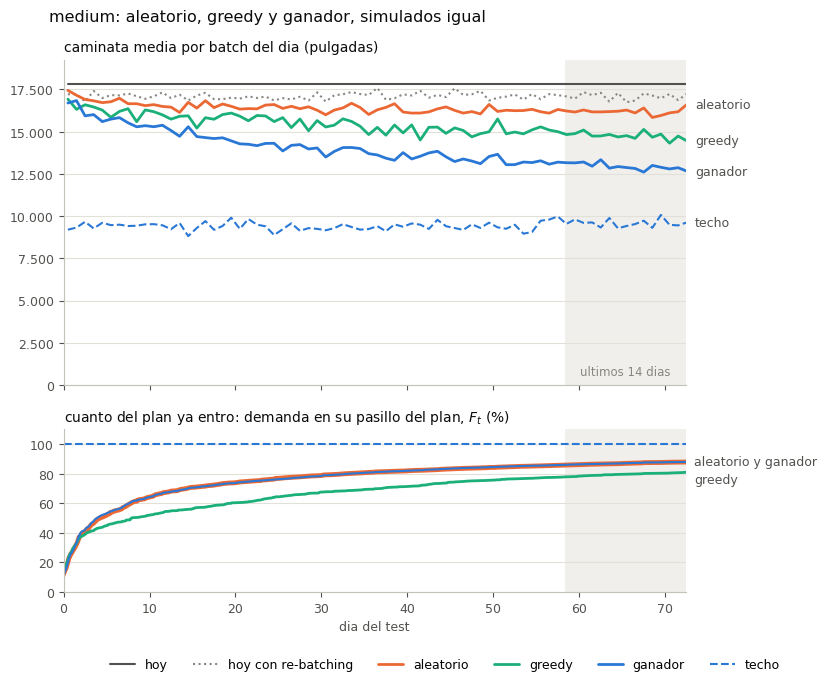

In [10]:
figura(datos["medium"])

**La caminata del ganador baja durante todo el test, la del greedy menos y la del aleatorio poco.** En
`medium` el ganador pasa de 16.692 pulgadas el primer dia a 12.661 el ultimo, el greedy de 16.919 a 14.453
y el aleatorio de 17.438 a 16.597. Hoy camina 17.824 todos los dias, hoy con re-batching alrededor de
17.200 y el techo entre 9.200 y 9.600. Abajo, el plan entra a la misma velocidad en el aleatorio y en el
ganador: $F_t$ pasa de cerca del 12% al 87,9% en los dos, asi que la diferencia de caminata entre ellos no
sale de cuanto plan entro, sino de que plan entra. El greedy entra mas lento y termina en 80,9% (ver
"Por que el greedy entra mas lento").

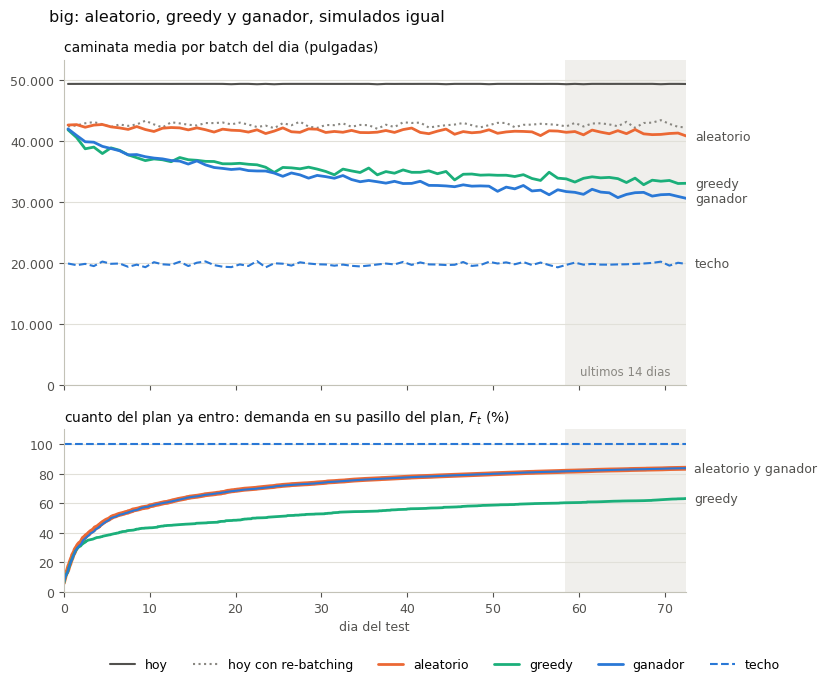

In [11]:
figura(datos["big"])

En `big` el ganador baja de 41.944 a 30.555 pulgadas, el greedy de 41.791 a 33.034 y el aleatorio de
42.576 a 40.758. Las dos primeras semanas el greedy camina un poco menos que el ganador (39.305 contra
39.796 pulgadas en la semana 0, seccion 5) y despues se queda atras. $F_t$ termina en 63,2% para el greedy
y en 83,7% para el aleatorio y el ganador.

### Por que el greedy entra mas lento

Los tres planes usan la misma regla, pero en el greedy $F_t$ termina mas abajo. Con la regla, un SKU entra
a su pasillo del plan solo si hay un hueco libre, y los huecos se liberan cuando se agota y se va alguno de
los SKUs que estan en ese pasillo pero que el plan pone en otro. Para cada plan y cada pasillo $a$, con el
deposito al empezar el test ($a_0(i)$ es el pasillo donde esta el SKU $i$),
$$E_a = \sum_{i:\ a^*(i) = a,\ a_0(i) \ne a} f_i, \qquad S_a = \sum_{i:\ a_0(i) = a,\ a^*(i) \ne a} f_i$$
son la demanda de los SKUs que tienen que entrar a $a$ y la de los que tienen que salir. Un SKU se repone
mas seguido cuanto mas se pide (la celda lo verifica con las reposiciones de train), asi que $E_a / S_a$
compara el ritmo al que llegan los SKUs que quieren entrar con el ritmo al que se liberan lugares. Si es
mucho mayor que 1, el pasillo se llena antes de que entren todos, y los que no caben van al pasillo libre
mas cercano. Se calcula en `medium`; armar el deposito de `big` dentro del notebook pide unos 3 GB.

In [12]:
from abs_affinity_based_slotting.experiments import build_plan, context
from abs_affinity_based_slotting.experiments.runner import sku_aisles

ctx = context(InstanceSpec("medium"))
demanda = pd.Series(ctx.instance.demand)                                 # f_i
loc_sku, _ = ctx.state_cut.location_arrays()
ocupada = loc_sku >= 0
al_corte = (pd.Series(ctx.location_aisle[ocupada], index=loc_sku[ocupada]).groupby(level=0).first()
            .reindex(range(ctx.instance.n_skus)))                         # a_0(i)

repos = (ctx.data.replen_train.groupby("sku").size().reindex(ctx.instance.sku_ids, fill_value=0)
         .reset_index(drop=True))
quintil = pd.qcut(demanda.rank(method="first"), 5, labels=False)
print("reposiciones de train por SKU, del quintil menos pedido al mas pedido:",
      repos.groupby(quintil).mean().round(2).tolist())

filas = {}
for corrida in CON_PLAN:
    plan = pd.Series(sku_aisles(ctx, build_plan(ctx, CORRIDAS[corrida][0])).to_numpy())   # a*(i)
    afuera = al_corte != plan
    filas[corrida, "demanda del plan (%)"] = 100 * demanda.groupby(plan).sum() / demanda.sum()
    filas[corrida, "E / S"] = (demanda[afuera].groupby(plan[afuera]).sum()
                               / demanda[afuera].groupby(al_corte[afuera]).sum())
presion = pd.DataFrame(filas).T
presion.columns = [f"pasillo {a + 1}" for a in presion.columns.astype(int)]
presion.round(2)

reposiciones de train por SKU, del quintil menos pedido al mas pedido: [0.54, 1.13, 1.79, 3.6, 25.78]


pasillo 1  pasillo 2  pasillo 3  pasillo 4  pasillo 5  pasillo 6  pasillo 7  pasillo 8
aleatorio 0 demanda del plan (%)      15.09      13.72      12.27      11.68      11.63      11.96      11.16      12.49
            E / S                      1.21       1.11       0.99       0.97       0.92       1.04       0.89       0.89
greedy      demanda del plan (%)      51.07      19.83      10.38       6.71       4.60       3.28       2.33       1.81
            E / S                      7.42       1.76       0.82       0.52       0.34       0.26       0.17       0.11
ganador     demanda del plan (%)      14.60      14.31      15.06      12.99      13.82      13.75      13.47       2.00
            E / S                      1.15       1.16       1.27       1.09       1.12       1.21       1.11       0.13

**El greedy pide un pasillo 1 que la regla no puede llenar.** Pone el 51% de la demanda de `medium` en el
pasillo 1, y los SKUs que tienen que entrar ahi suman 7,4 veces la demanda de los que tienen que salir.
Como un SKU se repone mas seguido cuanto mas se pide (de 0,54 reposiciones por SKU en train en el quintil
menos pedido a 25,8 en el mas pedido), los SKUs que quieren entrar llegan mucho mas rapido de lo que se
liberan lugares: el pasillo 1 se llena y los que sobran van al pasillo libre mas cercano, fuera de su
pasillo del plan. En el aleatorio y en el ganador la demanda se reparte pareja entre pasillos y $E_a/S_a$
queda entre 0,9 y 1,3 (salvo el ultimo pasillo del ganador, casi vacio en el plan), asi que lo que entra y
lo que sale se equilibran.

## 5. Se estabilizo?

Se mira la caminata media de cada semana completa del test (semana $s$ = dias $7s$ a $7s + 6$; las
semanas 0 a 9; los dias 70 a 72 quedan afuera).

**El ruido.** El techo tiene el plan entero desde el principio y cada SKU vuelve siempre a su lugar, asi
que su deposito no cambia en todo el test y su caminata semanal varia solo porque cada semana tiene otros
pedidos. Sea $\sigma$ el desvio de sus medias semanales. (El aleatorio no sirve para esto: su caminata
baja a lo largo del test, por lo que muestra la seccion 3.)

**Regla.** Si las semanas son independientes, la diferencia entre las medias de dos semanas tiene desvio
$\sqrt{2}\,\sigma$. El ganador sigue cambiando si entre la semana 5 y la 9 su caminata semanal $M_s$ se
movio mas que dos veces eso:
$$|M_9 - M_5| > 2\sqrt{2}\,\sigma .$$

In [13]:
def por_semana(d):
    semana = lambda dia: dia // 7
    dias = d.logs["hoy"].groupby(semana(d.logs["hoy"]["dia"]))["dia"].nunique()
    completas = dias.index[dias == 7]
    t = pd.DataFrame({c: d.logs[c].groupby(semana(d.logs[c]["dia"]))["distance"].mean()
                      for c in (ALEATORIO, "greedy", "ganador", "techo")}).loc[completas]
    t["ganador vs aleatorio (%)"] = 100 * (t["ganador"] / t[ALEATORIO] - 1)
    t["cambio del ganador"] = t["ganador"].diff()
    p = d.pasos["ganador"]
    por = p.groupby(semana(p["dia"].astype(int)))
    t["F del ganador (%)"] = 100 * por["demand_in_plan_aisle"].mean()
    t["pasillos por orden del ganador"] = por["aisles_per_order"].mean()
    return t.rename(columns={ALEATORIO: "aleatorio"}).rename_axis("semana")


semanas = {n: por_semana(d) for n, d in datos.items()}
semanas["medium"].round(2)

,aleatorio,greedy,ganador,techo,ganador vs aleatorio (%),cambio del ganador,F del ganador (%),pasillos por orden del ganador
semana,,,,,,,,
0,16967.90,16373.67,16090.53,9427.65,-5.17,NaN,43.54,2.57
1,16499.75,15998.78,15227.14,9446.78,-7.71,-863.39,64.77,2.12
2,16548.57,15816.56,14650.82,9368.41,-11.47,-576.32,72.20,1.91
3,16444.42,15700.99,14186.12,9352.00,-13.73,-464.70,76.05,1.78
4,16359.70,15433.72,13921.11,9293.97,-14.91,-265.01,79.22,1.70
5,16246.68,15016.61,13529.52,9382.70,-16.72,-391.59,81.61,1.62
6,16222.48,15034.23,13431.09,9382.99,-17.21,-98.43,83.53,1.57
7,16291.68,15115.38,13269.23,9345.64,-18.55,-161.86,85.00,1.53
8,16198.08,14912.71,13150.08,9664.91,-18.82,-119.15,86.22,1.48


In [14]:
semanas["big"].round(2)

,aleatorio,greedy,ganador,techo,ganador vs aleatorio (%),cambio del ganador,F del ganador (%),pasillos por orden del ganador
semana,,,,,,,,
0,42431.82,39304.82,39795.66,19827.52,-6.21,NaN,38.12,2.80
1,41979.38,37054.10,37205.44,19728.64,-11.37,-2590.22,58.48,2.32
2,41771.68,36524.18,35816.32,19687.98,-14.26,-1389.12,66.39,2.08
3,41560.82,35609.99,34745.92,19786.31,-16.40,-1070.40,71.20,1.94
4,41590.17,35092.00,33916.55,19656.85,-18.45,-829.37,74.53,1.85
5,41576.46,34923.25,33223.91,19834.03,-20.09,-692.64,77.06,1.78
6,41415.59,34521.76,32626.93,19728.43,-21.22,-596.98,78.88,1.72
7,41405.17,34144.34,32166.13,19967.41,-22.31,-460.80,80.49,1.66
8,41461.26,33939.04,31603.09,19699.29,-23.78,-563.04,81.82,1.62


In [15]:
def estabilidad(t):
    sigma = t["techo"].std()
    cambio = t["ganador"].iloc[-1] - t["ganador"].iloc[-5]          # semana 9 menos semana 5
    umbral = 2 * np.sqrt(2) * sigma
    return {"sigma (pulgadas)": sigma, "umbral 2*sqrt(2)*sigma": umbral, "cambio del ganador, semanas 5 a 9": cambio,
            "por semana": cambio / 4, "en % de la semana 5": 100 * cambio / t["ganador"].iloc[-5],
            "veces el umbral": abs(cambio) / umbral}


estable = pd.DataFrame({n: estabilidad(t) for n, t in semanas.items()}).T.round(2)
estable["sigue cambiando"] = estable["veces el umbral"] > 1
estable

,sigma (pulgadas),umbral 2*sqrt(2)*sigma,"cambio del ganador, semanas 5 a 9",por semana,en % de la semana 5,veces el umbral,sigue cambiando
medium,116.57,329.70,-678.38,-169.59,-5.01,2.06,True
big,97.67,276.24,-2008.25,-502.06,-6.04,7.27,True


**En 72 dias el ganador no se estabiliza.** El techo varia de una semana a otra con un desvio de 117
pulgadas en `medium` y 98 en `big`. Entre las semanas 5 y 9 el ganador bajo 678 pulgadas en `medium` (5,0%
de su caminata de la semana 5, unas 170 por semana), 2,1 veces el umbral, y 2.008 en `big` (6,0%, unas 500
por semana), 7,3 veces el umbral. El ritmo se frena: en `medium` bajo 863 pulgadas de la semana 0 a la 1, y
entre 98 y 392 en cada una de las semanas 5 a 9. La ventaja sobre el aleatorio tambien sigue creciendo:
pasa de 16,7% en la semana 5 a 20,4% en la 9 en `medium`, y de 20,1% a 24,4% en `big`.

## 6. Cuanto falta para el techo

Entre el aleatorio (un plan que no usa datos) y el techo (el plan ganador entero) hay un trecho. La tabla
dice que parte de ese trecho recorrio el ganador en la ultima semana completa,
$100\,(M^{\text{aleatorio}} - M^{\text{ganador}}) / (M^{\text{aleatorio}} - M^{\text{techo}})$, con el
aleatorio y el ganador en esa semana y el techo en su media de todo el test, y con cuanto del plan
adentro.

In [16]:
def falta(nombre):
    d, t = datos[nombre], semanas[nombre]
    ultima = t.index[-1]                                                  # ultima semana completa
    a, g = t["aleatorio"].iloc[-1], t["ganador"].iloc[-1]
    techo = d.logs["techo"]["distance"].mean()
    return {"F del ganador (%)": t["F del ganador (%)"].iloc[-1], "aleatorio": a, "ganador": g, "techo": techo,
            "trecho recorrido (%)": 100 * (a - g) / (a - techo),
            "pasillos por orden: ganador": t["pasillos por orden del ganador"].iloc[-1],
            "pasillos por orden: plan entero": fila(nombre, "ganador")["aisles_per_order"],
            "pasillos por batch: ganador": d.logs["ganador"].query("dia // 7 == @ultima")["n_aisles"].mean(),
            "pasillos por batch: techo": d.logs["techo"]["n_aisles"].mean()}


pd.DataFrame({n: falta(n) for n in DEPOSITOS}).T.round(2)

,F del ganador (%),aleatorio,ganador,techo,trecho recorrido (%),pasillos por orden: ganador,pasillos por orden: plan entero,pasillos por batch: ganador,pasillos por batch: techo
medium,87.28,16133.79,12851.14,9428.24,48.95,1.45,1.03,5.20,3.50
big,82.93,41279.13,31215.66,19780.09,46.81,1.59,1.04,9.29,5.29


**Al final del test el ganador recorrio la mitad del camino entre el aleatorio y el techo:** 49% en `medium`
y 47% en `big`, con el 87% y el 83% de la demanda ya en su pasillo del plan. La demanda que falta pesa mucho
mas que su parte porque el S cobra pasillos enteros: un batch entra a un pasillo con que una sola de sus
lineas este ahi. Por eso una orden del ganador todavia toca 1,45 pasillos contra 1,03 del plan entero, y un
batch visita 5,2 pasillos contra 3,5 del techo (en `big`, 1,59 contra 1,04 y 9,3 contra 5,3).

## 7. Lectura

1. **El plan ganador vale un 20% de caminata contra un plan sin datos, y no es suerte.** Simulado igual que
   un plan aleatorio, el ganador camina 19,9% menos al final en `medium` y 24,3% menos en `big` (14,6% y
   18,0% en promedio sobre el test). Tres sorteos del aleatorio difieren entre si en menos de un punto.
2. **Contra el greedy, el ganador gana 12,4% al final en `medium` y 6,7% en `big`** (9,1% y 3,6% en
   promedio). En `big` el greedy va a la par las dos primeras semanas y despues se queda: entra mas lento
   (63% de su demanda en su pasillo al final, contra 84%). En `medium` se ve por que: pone la mitad de la
   demanda en el pasillo 1, y la regla no logra vaciarlo de los SKUs que no van ahi.
3. **Lo que el ganador le gana a hoy se reparte en cuatro partes.** En `medium`, al final del test: el
   re-batching -4,2%, la regla 5,1 puntos mas, ubicar por demanda 7,8 mas y ubicar por merchant 10,3 mas,
   hasta -27,4%. La parte de la regla no viene del plan: viene de que muda menos SKUs, asi que los pasillos
   con que se arman los batches siguen siendo ciertos mientras se recorren.
4. **En 72 dias no se estabiliza.** En las semanas 5 a 9 el ganador siguio bajando, 2,1 veces (`medium`) y
   7,3 veces (`big`) lo que explica el ruido, y su ventaja sobre el aleatorio siguio creciendo. Al final
   recorrio la mitad del camino entre el aleatorio y el techo.
5. **Que reportar.** La comparacion justa del plan es contra otros planes simulados igual: -19,9% contra el
   aleatorio y -12,4% contra el greedy en `medium` al final (-24,3% y -6,7% en `big`). El final es donde
   estaba la caminata al terminar el test, no donde se estabiliza: deberia seguir bajando hacia el techo, y
   este test no alcanza para saber cuanto.